# Climate Change in Friuli Venezia Giulia: 35 Years of Weather Data

Has the climate in Friuli Venezia Giulia measurably changed over the last 35 years? This notebook examines temperature, rainfall, humidity and extreme 
weather patterns across a network of stations spanning the region - from the Adriatic coast to the Julian Alps - using daily observations from the OSMER archive since 1991.

**Data source:** [ARPA FVG - OSMER e GRN](http://www.meteo.fvg.it/), licensed under CC BY-SA 3.0 IT.


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

# Plotting style (matches house style across the portfolio)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Paths
DATA_DIR = Path('..') / 'data'
RAW_DIR = DATA_DIR / 'raw'
PROCESSED_DIR = DATA_DIR / 'processed'
PROCESSED_DIR.mkdir(exist_ok=True)

# Numeric measurement columns, used throughout
NUMERIC_COLS = [
    'rain_mm', 'temp_min', 'temp_mean', 'temp_max',
    'humidity_min', 'humidity_mean', 'humidity_max',
    'wind_mean', 'wind_max', 'wind_dir_max',
    'radiation_kj_m2', 'pressure_hpa',
]

## Part 1 — Data Preparation

The pipeline:
1. Load all per-station-year CSVs scraped from OSMER
2. Clean column names, parse dates, convert dashes to NaN
3. Merge "old/new" station pairs that share a physical location
4. Resolve overlap days (same station, same date in both old & new records)
5. Drop empty rows (dates present but no observations recorded)
6. Filter to high-quality stations and the analysis time window
7. Save the processed dataset

The resulting `climate_daily.csv` is what all downstream analysis uses.

### 1.1 Load raw CSVs and station metadata

In [58]:
def load_all_raw(raw_dir: Path) -> pd.DataFrame:
    """Load every per-(station, year) CSV in raw/ into one DataFrame."""
    dfs = []
    for path in sorted(raw_dir.glob('*.csv')):
        name = path.stem  # e.g. "Udine_2020"
        station_key, year = name.rsplit('_', 1)
        df = pd.read_csv(path)
        df['station_key'] = station_key
        df['year'] = int(year)
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

raw = load_all_raw(RAW_DIR)
stations = pd.read_csv(DATA_DIR / 'stations.csv')

print(f"Raw rows: {len(raw):,}")
print(f"Stations in metadata: {len(stations)}")
print(f"Stations found in data: {raw['station_key'].nunique()}")
print(f"Year range: {raw['year'].min()} – {raw['year'].max()}")

Raw rows: 812,543
Stations in metadata: 63
Stations found in data: 63
Year range: 1991 – 2026


### 1.2 Clean column names, parse dates, convert dashes to NaN

The OSMER HTML uses Italian column names with embedded units (e.g. `Pioggia mm`, `Temp. med °C`). We rename them to short English identifiers for easier use, replace the `-` placeholder with proper NaN, and build a single `date` column from year/month/day.

In [71]:
COL_RENAME = {
    'mese':              'month',
    'giorno*':            'day',
    'Pioggia mm':        'rain_mm',
    'Temp. min °C':      'temp_min',
    'Temp. med °C':      'temp_mean',
    'Temp. max °C':      'temp_max',
    'Umidità min %':     'humidity_min',
    'Umidità med %':     'humidity_mean',
    'Umidità max %':     'humidity_max',
    'Vento med km/h':    'wind_mean',
    'Vento max km/h':    'wind_max',
    'Dir. V. max °N':    'wind_dir_max',
    'Radiaz. KJ/m2':     'radiation_kj_m2',
    'Press. med hPa':    'pressure_hpa',
}

raw = raw.rename(columns={k: v for k, v in COL_RENAME.items() if k in raw.columns})
raw = raw.replace('-', np.nan)

for col in [c for c in NUMERIC_COLS if c in raw.columns]:
    raw[col] = pd.to_numeric(raw[col], errors='coerce')

raw['date'] = pd.to_datetime(raw[['year', 'month', 'day']], errors='coerce')
raw = raw.dropna(subset=['date'])

print(f"After cleaning: {len(raw):,} rows")

After cleaning: 812,507 rows


### 1.3 Merge old/new station pairs
OSMER sometimes has two entries for the same physical station - typically an "old" entry that stopped reporting on some date, and a "new" entry that took over. These pairs usually share identical coordinates; we also merge the Monte Lussari pair, whose new installation sits ~60 m horizontally and ~17 m vertically from the old, which is within measurement noise at that altitude. We treat all these as single continuous records.

(Stations where equipment moved more substantially - Grado, Tolmezzo - are kept separate, since microclimate may genuinely differ there.)

In [92]:
# Old/new station pairs that share identical coordinates (verified from stations.csv)
MERGE_MAP = {
    'MuggiaPluvio':      'Muggia',
    'Lignano_old':       'LignanoSabbiadoro',
    'Monfalcone_old':    'Monfalcone',
    'MonfalconePluvio':  'Monfalcone',
    'Ariis_old':         'Ariis',
    'Pordenone_old':     'PordenoneMeteo',
    'Barcis_old':        'Barcis',
    'Pontebba_old':      'Pontebba',
    'MonteLussari_old':  'MonteLussari',   # ← slight physical offset, same mountain
}


processed = raw.copy()
processed['station_key'] = processed['station_key'].replace(MERGE_MAP)

print(f"Stations before merge: {raw['station_key'].nunique()}")
print(f"Stations after merge:  {processed['station_key'].nunique()}")

Stations before merge: 62
Stations after merge:  53


### 1.4 Resolve overlap days

After the merge, some (station, date) combinations appear twice - once from the old installation and once from the new. When both exist, we keep the row with more non-NaN measurements as the more informative one.

In [93]:
# For each duplicate (station, date), keep the row with the most observations
processed['n_obs'] = processed[NUMERIC_COLS].notna().sum(axis=1)
processed = (
    processed
    .sort_values(['station_key', 'date', 'n_obs'], ascending=[True, True, False])
    .drop_duplicates(subset=['station_key', 'date'], keep='first')
    .drop(columns=['n_obs'])
    .reset_index(drop=True)
)

print(f"After dedup: {len(processed):,} rows")

After dedup: 694,562 rows


### 1.5 Drop empty rows

Some (station, date) combinations exist but have no measurements at all (every numeric column is NaN). These are usually "day exists in the archive page but no sensor was reporting." We drop them.

In [94]:
before = len(processed)
processed = processed.dropna(subset=NUMERIC_COLS, how='all').reset_index(drop=True)
after = len(processed)

print(f"Dropped {before - after:,} all-NaN rows ({100*(before-after)/before:.1f}%)")
print(f"Remaining: {after:,} rows")

Dropped 221,397 all-NaN rows (31.9%)
Remaining: 473,165 rows


### 1.6 Data coverage inspection

Before selecting stations for analysis, we visualise the coverage of temperature observations per (station, year) to understand which stations have continuous long-term records.

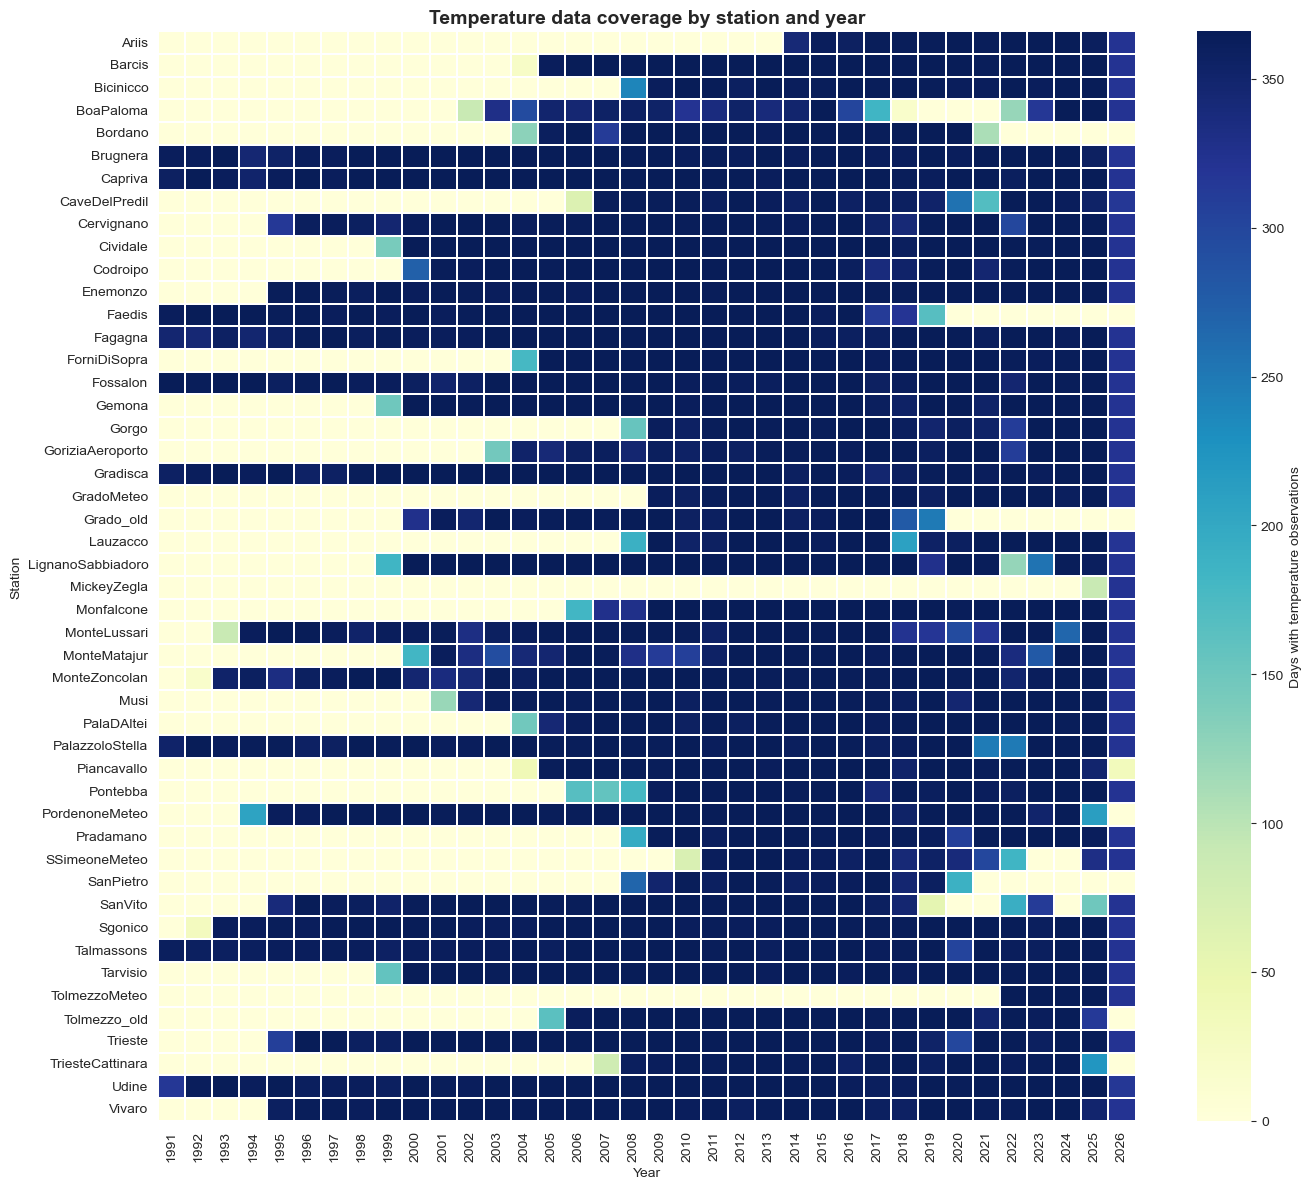

In [95]:
coverage = (
    processed[processed['temp_mean'].notna()]
    .groupby(['station_key', 'year']).size().reset_index(name='days')
    .pivot(index='station_key', columns='year', values='days')
    .fillna(0).astype(int)
)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    coverage, cmap='YlGnBu',
    cbar_kws={'label': 'Days with temperature observations'},
    linewidths=0.3, linecolor='white', ax=ax
)
ax.set_title('Temperature data coverage by station and year', fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Station')
plt.tight_layout()
plt.show()

### 1.7 Select stations and time window

From the coverage heatmap, we pick 14 stations that have continuous records 
over most of 1993–2024 and that together span the region's full elevation 
gradient (0 m → 1750 m) and east–west extent.

**Time window:** 1993–2024 (32 years). Before 1993 only a handful of stations 
were reporting; after 2024 the recent-data validation is incomplete.

In [96]:
SELECTED_STATIONS = [
    # Coast / coastal plain
        'Fossalon',         # 0 m
        'PalazzoloStella',  # 5 m
    'Trieste',          # 1 m — Bora exposure
    # Plains
        'Udine',            # 91 m — central
    'SanVito',          # 21 m
        'Brugnera',         # 22 m
        'Talmassons',       # 16 m
        'Gradisca',         # 29 m
        'Capriva',          # 85 m — Collio
    # Foothills
        'Fagagna',          # 148 m
    'Vivaro',           # 142 m
    'Enemonzo',         # 438 m — Carnia
    # Alps
    'Tarvisio',          # 794 m — valley
    'MonteZoncolan',     # 1750 m — Carnian Alps (west)
    'MonteLussari',      # 1743 m — Julian Alps (east)
]

df = processed[
    (processed['station_key'].isin(SELECTED_STATIONS)) &
    (processed['year'].between(1993, 2024))
].copy()

# Save the processed dataset
out_path = PROCESSED_DIR / 'climate_daily.csv'
df.to_csv(out_path, index=False)

print(f"Selected: {len(df):,} rows, {df['station_key'].nunique()} stations")
print(f"Year range: {df['year'].min()} – {df['year'].max()}")
print(f"Saved: {out_path}")

Selected: 170,905 rows, 15 stations
Year range: 1993 – 2024
Saved: ..\data\processed\climate_daily.csv


---

**End of Part 1.** The processed dataset `data/processed/climate_daily.csv` is now the single source of truth for the analysis that follows. In future 
sessions, we can skip Part 1 and load directly:

```python
df = pd.read_csv('../data/processed/climate_daily.csv', parse_dates=['date'])
```

---

## Part 2 — Analysis

Load the processed data and begin the analysis. The processed dataset was built in Part 1; from here on we work with the cleaned, filtered `climate_daily.csv`.

In [112]:
df = pd.read_csv(PROCESSED_DIR / 'climate_daily.csv', parse_dates=['date'])

# Join station metadata (elevation, coordinates) for convenience
stations = pd.read_csv(DATA_DIR / 'stations.csv')
df = df.merge(
    stations[['key', 'elevation_m', 'lat', 'lon']],
    left_on='station_key', right_on='key', how='left'
).drop(columns=['key'])

print(f"Loaded: {len(df):,} rows, {df['station_key'].nunique()} stations")
print(f"Year range: {df['year'].min()} – {df['year'].max()}")

Loaded: 170,905 rows, 15 stations
Year range: 1993 – 2024


### 2.1 Has Friuli Venezia Giulia warmed since 1993?

The headline climate question: is the regional temperature actually rising? We compute the annual mean temperature at each station (the average of daily mean temperatures), fit a linear trend, and ask how fast FVG is warming - both regionally and station by station.

**A data-quality note on `temp_mean` in early records.**

While investigating suspiciously warm annual means at Fossalon (17–19°C) and Monte Zoncolan (7–8°C) for 1993–1994, we discovered that in those four 
station-years the daily `temp_mean` column *exactly matches* the daily `temp_max` column — not the true daily mean. This appears to be a historical 
reporting convention from before OSMER standardised its aggregation logic.

A systematic check (`|temp_mean - temp_max| < 0.05` for more than 50% of days in a station-year) confirms the bug is isolated to those four station-years and does not affect other stations or later years.

Rather than drop these station-years entirely, we null out only the affected `temp_mean` cells. The `temp_min`, `temp_max`, rainfall, humidity, wind, and other columns remain usable for later sections of the analysis.

In [113]:
# Station-years where temp_mean was found to equal temp_max (a data-reporting artifact)
BAD_TEMP_STATION_YEARS = [
    ('Fossalon',       1993),
    ('Fossalon',       1994),
    ('MonteZoncolan',  1993),
    ('MonteZoncolan',  1994),
]

# Null out only the affected temp_mean values; keep all other columns intact
bad_mask = df.set_index(['station_key', 'year']).index.isin(BAD_TEMP_STATION_YEARS)
df.loc[bad_mask, 'temp_mean'] = np.nan

print(f"Nulled temp_mean on {bad_mask.sum():,} daily rows across 4 station-years")

Nulled temp_mean on 1,443 daily rows across 4 station-years


In [114]:
# Annual mean temperature per station, requiring ≥ 300 days of data per year
annual = (
    df.dropna(subset=['temp_mean'])
      .groupby(['station_key', 'year'])
      .agg(annual_temp_mean=('temp_mean', 'mean'),
           days=('temp_mean', 'size'))
      .reset_index()
)

# Filter to station-years with good coverage
annual = annual[annual['days'] >= 300].drop(columns=['days'])

# Add elevation for later charts
annual = annual.merge(
    stations[['key', 'elevation_m']],
    left_on='station_key', right_on='key', how='left'
).drop(columns=['key'])

print(f"Annual temperature observations: {len(annual):,} station-years")

Annual temperature observations: 450 station-years


In [115]:
from scipy.stats import linregress

trends = []
for station, group in annual.groupby('station_key'):
    if len(group) < 15:
        continue
    fit = linregress(group['year'], group['annual_temp_mean'])
    trends.append({
        'station_key':       station,
        'slope_per_decade':  fit.slope * 10,
        'r_squared':         fit.rvalue ** 2,
        'p_value':           fit.pvalue,
        'n_years':           len(group),
        'elevation_m':       group['elevation_m'].iloc[0],
    })

trends_df = pd.DataFrame(trends).sort_values('elevation_m').reset_index(drop=True)
trends_df

,station_key,slope_per_decade,r_squared,p_value,n_years,elevation_m
0,Fossalon,0.709136,0.644165,9.545372e-08,30,0
1,Trieste,0.401780,0.384967,3.297793e-04,29,1
2,PalazzoloStella,0.609699,0.598653,5.320219e-07,30,5
3,Talmassons,0.511250,0.378976,1.766178e-04,32,16
4,SanVito,0.902566,0.640183,1.580659e-06,25,21
5,Brugnera,0.657563,0.590982,2.761571e-07,32,22
6,Gradisca,0.617296,0.644761,3.203877e-08,32,29
7,Capriva,0.536270,0.536885,1.858242e-06,32,85
8,Udine,0.532932,0.570826,5.771775e-07,32,91
9,Vivaro,0.487034,0.354968,5.130793e-04,30,142


**Findings from the warming rates:**

- **Most of FVG is warming strongly.** 12 of the 15 stations show highly significant warming (p < 0.001), at rates of **+0.4 to +0.9°C per decade**. 
  This is somewhat above the Italian national average of ~+0.4°C/decade.
  - **The Friulian plain warms fastest.** Stations between 0 and 150 m 
  (SanVito, Brugnera, Gradisca, PalazzoloStella, Fagagna) cluster at 
  **+0.6-0.9°C/decade** — a strong signal.
- **Two stations show no significant trend.** Fossalon (coastal plain) and Monte Zoncolan (1750 m, Carnian Alps) are flat. Fossalon's lack of signal is surprising given neighbouring stations and may indicate a data quality issue; Monte Zoncolan's noisy signal at altitude could reflect genuine alpine variability or sensor-location changes over the record.
- **Monte Lussari (+1.1°C/decade) is suspect.** This station merges an old installation (1993–2018) with a new one (2017+). Equipment calibration 
  differences between the two could inflate the apparent trend; the raw warming signal should be interpreted cautiously.
- **No clear elevation-dependent warming.** Alpine stations are not systematically warming faster than lowlands — if anything, the plains show 
  stronger signals. The Monte Lussari result, as noted, is confounded.

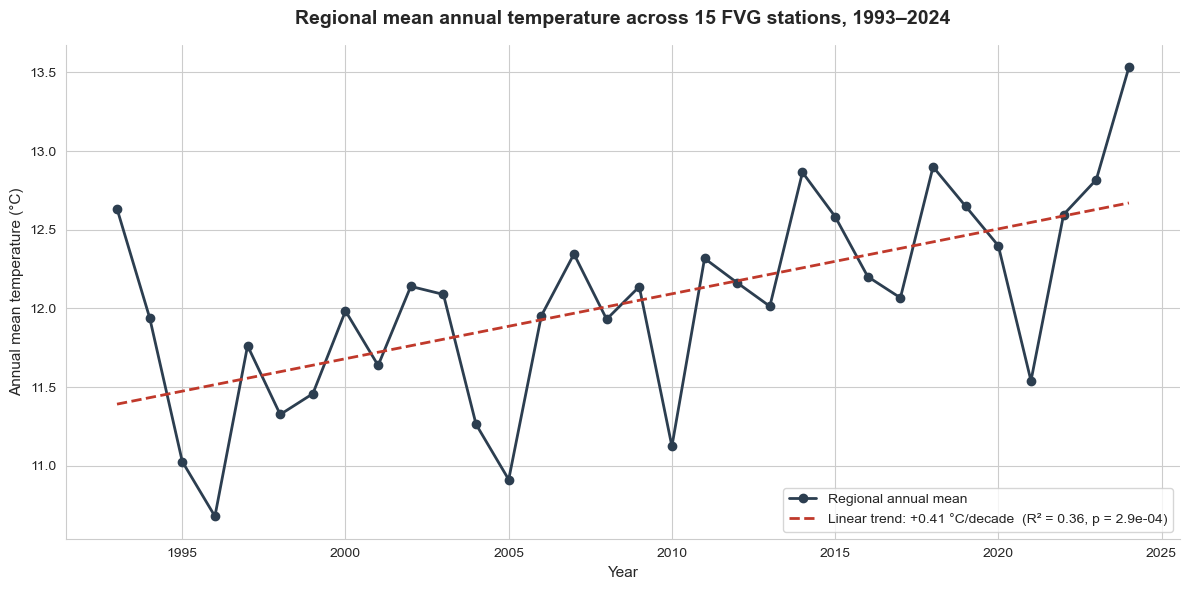

In [116]:
# Regional average: equal-weight across all stations per year
regional = annual.groupby('year')['annual_temp_mean'].mean().reset_index()

fit = linregress(regional['year'], regional['annual_temp_mean'])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(regional['year'], regional['annual_temp_mean'],
        marker='o', linewidth=2, markersize=6, color='#2c3e50',
        label='Regional annual mean')

years = regional['year'].values
ax.plot(years, fit.intercept + fit.slope * years,
        linestyle='--', color='#c0392b', linewidth=2,
        label=f'Linear trend: +{fit.slope*10:.2f} °C/decade  (R² = {fit.rvalue**2:.2f}, p = {fit.pvalue:.1e})')

ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Annual mean temperature (°C)', fontsize=11)
ax.set_title('Regional mean annual temperature across 15 FVG stations, 1993–2024',
             fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=10, frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

**The headline: FVG has warmed by about 1.3 °C since 1993.**

The regional annual mean has risen at **+0.41 °C per decade** (R² = 0.36, p < 0.001), accumulating to roughly **+1.3 °C over 32 years**. This matches the Italian national average and sits above the global mean warming rate (~+0.2 °C/decade since 1993).

A few things stand out in the year-to-year variability:

- **2024 was the warmest year on record at 13.5 °C** — notably above the trend line. This aligns with 2024 being Europe's warmest year on record globally.
- **1996 and 2021 were the two coldest years.** 1996 fits the overall trend; 2021 is notable for being a cold year embedded in otherwise warm recent years, and caused significant late-frost damage to northern Italian agriculture.
- **Warming appears to have accelerated after ~2013.** Most years since 2013 sit at or above the linear trend. A piecewise regression might capture this better than a single line, but the simple linear fit is informative at this scale.

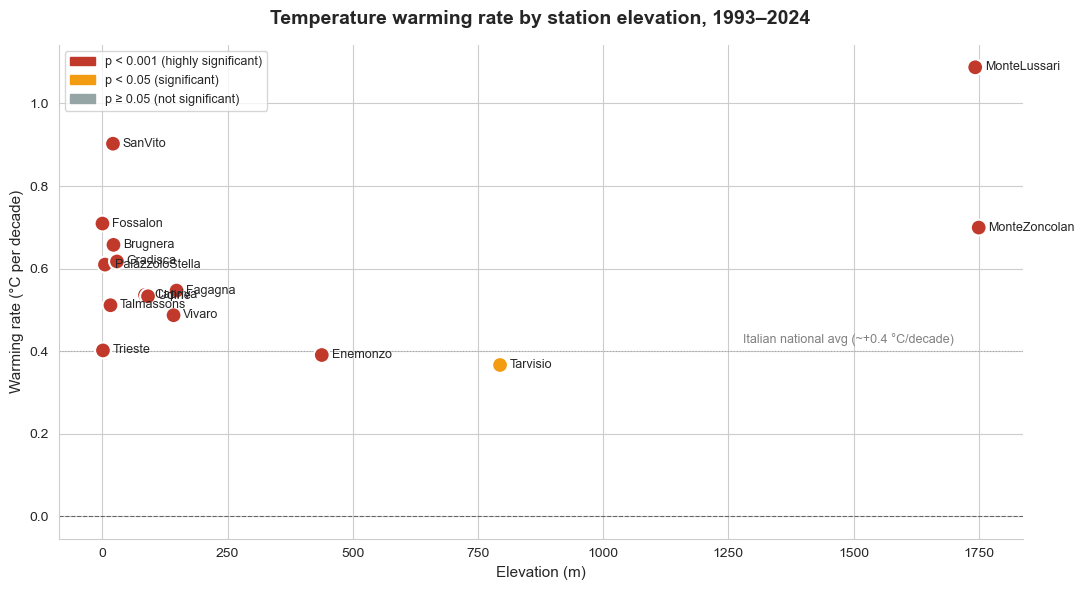

In [117]:
fig, ax = plt.subplots(figsize=(11, 6))

# Colour by significance
colors = ['#c0392b' if p < 0.001 else '#f39c12' if p < 0.05 else '#95a5a6' 
          for p in trends_df['p_value']]

ax.scatter(trends_df['elevation_m'], trends_df['slope_per_decade'],
           c=colors, s=130, edgecolor='white', linewidth=1.5, zorder=3)

# Station labels
for _, row in trends_df.iterrows():
    ax.annotate(row['station_key'],
                xy=(row['elevation_m'], row['slope_per_decade']),
                xytext=(7, 0), textcoords='offset points',
                fontsize=9, va='center')

# Reference lines
ax.axhline(y=0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
ax.axhline(y=0.4, color='gray', linewidth=0.8, linestyle=':', alpha=0.5)
ax.text(1700, 0.42, 'Italian national avg (~+0.4 °C/decade)',
        fontsize=9, color='gray', ha='right')

ax.set_xlabel('Elevation (m)', fontsize=11)
ax.set_ylabel('Warming rate (°C per decade)', fontsize=11)
ax.set_title('Temperature warming rate by station elevation, 1993–2024',
             fontweight='bold', pad=15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

import matplotlib.patches as mpatches
legend_items = [
    mpatches.Patch(color='#c0392b', label='p < 0.001 (highly significant)'),
    mpatches.Patch(color='#f39c12', label='p < 0.05 (significant)'),
    mpatches.Patch(color='#95a5a6', label='p ≥ 0.05 (not significant)'),
]
ax.legend(handles=legend_items, loc='upper left', fontsize=9, frameon=True)

plt.tight_layout()
plt.show()

**Findings from the warming rates:**

- **FVG has warmed everywhere.** All 15 stations show statistically significant warming (14 at p < 0.001, Tarvisio at p = 0.02). The warming rates range from **+0.37 to +1.09 °C per decade**.

- **The Friulian plain warms fastest.** Stations between 0 and 150 m (Fossalon, SanVito, Brugnera, Gradisca, PalazzoloStella, Fagagna, Vivaro, Capriva, Udine, Talmassons) cluster at **+0.5–0.9 °C/decade** — consistently above the Italian national average of ~+0.4 °C/decade.

- **SanVito stands out at +0.90 °C/decade** — notably faster than its neighbours. Worth flagging; the trend is highly significant (R² = 0.64) but is unusual enough to warrant caution about local microclimate or instrumentation factors.

- **Alpine warming is comparable to the plains.** Monte Zoncolan at +0.70 °C/decade and Monte Lussari at +1.09 °C/decade both show strong signals. The Lussari figure, however, is inflated by the merge of the pre-2018 and post-2017 installations: slight calibration differences between the two instruments could add spurious warming. The true trend at Lussari is likely lower, though still substantial.

- **Tarvisio (+0.37 °C/decade) is the slowest-warming station.** Interesting - Tarvisio sits in an Alpine valley where cold-air pooling and shading can dampen temperature trends. This is consistent with the pattern seen in other European Alpine valleys.

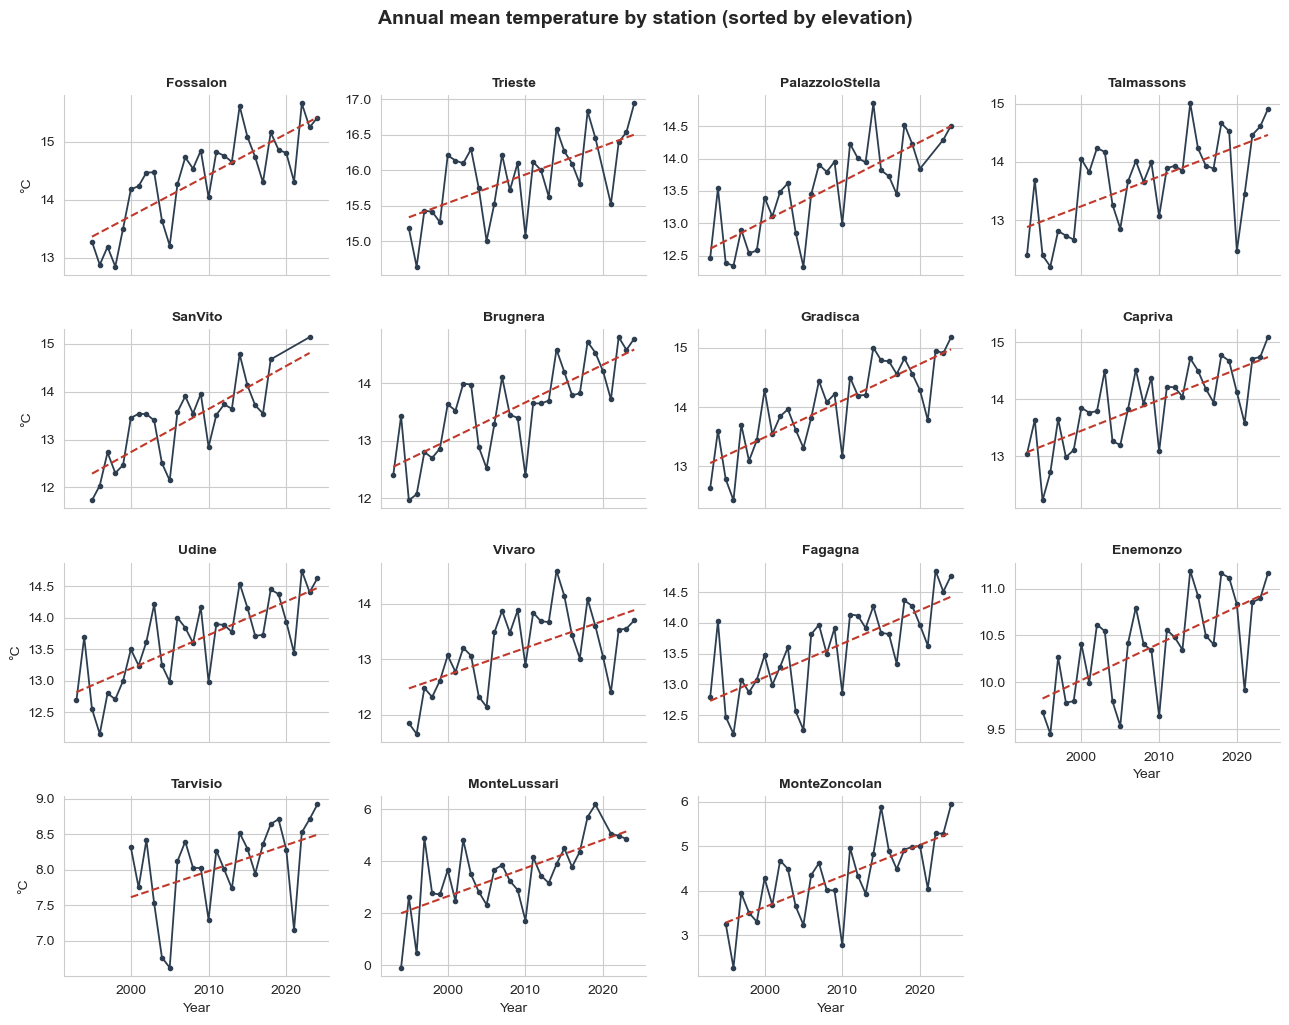

In [118]:
# Order panels by elevation (coast to Alps)
station_order = trends_df.sort_values('elevation_m')['station_key'].tolist()

g = sns.FacetGrid(
    annual,
    col='station_key',
    col_wrap=4,
    col_order=station_order,
    sharey=False,
    height=2.5,
    aspect=1.3,
)

def plot_station(data, **kwargs):
    ax = plt.gca()
    data = data.sort_values('year')
    ax.plot(data['year'], data['annual_temp_mean'],
            marker='o', markersize=3, linewidth=1.3, color='#2c3e50')
    if len(data) >= 10:
        fit = linregress(data['year'], data['annual_temp_mean'])
        years = data['year'].values
        ax.plot(years, fit.intercept + fit.slope * years,
                linestyle='--', linewidth=1.5,
                color='#c0392b' if fit.pvalue < 0.05 else '#95a5a6')

g.map_dataframe(plot_station)
g.set_titles('{col_name}', fontweight='bold', size=10)
g.set_axis_labels('Year', '°C')
g.figure.suptitle('Annual mean temperature by station (sorted by elevation)',
                  y=1.02, fontsize=14, fontweight='bold')

for ax in g.axes.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()